## Inflation forecastin


In [32]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / 'modelling').is_dir() and (p / 'data').is_dir()
)
RESULTS = PROJECT_ROOT / 'data' / 'processed' / 'model_results'
BASELINE = RESULTS / 'baseline'
MACRO = RESULTS / 'macro'

forecasts = pd.read_csv(BASELINE / 'forecasts.csv', parse_dates=['Date'])
metrics = pd.read_csv(BASELINE / 'metrics.csv')
baseline_parameters = json.loads((BASELINE / 'parameters.json').read_text(encoding='utf-8'))['models']
macro_forecasts = pd.read_csv(MACRO / 'forecasts.csv', parse_dates=['Date'])
macro_metrics = pd.read_csv(MACRO / 'metrics.csv').sort_values('rmse').reset_index(drop=True)
macro_details = json.loads((MACRO / 'parameters.json').read_text(encoding='utf-8'))
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})


**Existing models**


,model,rmse,mae,mean_error_actual_minus_forecast
0,AR(1),0.2652,0.1956,0.0675
1,ARX + sentiment,0.2667,0.1967,0.0659
2,AR-HMM,0.2695,0.1961,0.0744
3,LASSO inflation + sentiment,0.2863,0.2069,0.1038
4,LASSO inflation only,0.2915,0.2099,0.1093
5,AR-HMM + sentiment,0.3008,0.2137,0.0887
6,HMM,0.3306,0.2345,0.1264


Common period: 2017-01 to 2023-12; 84 months


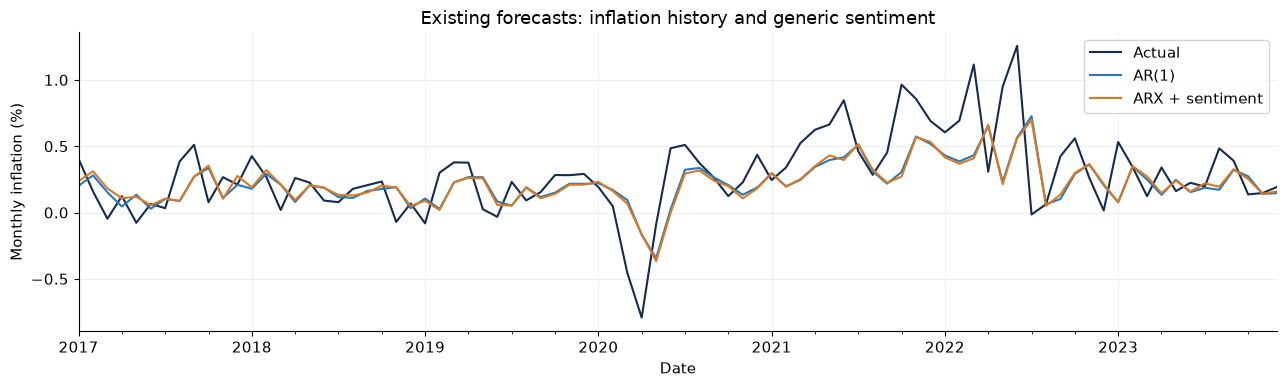

In [33]:
display(metrics.round(4))
print(f"Common period: {forecasts['Date'].min():%Y-%m} to {forecasts['Date'].max():%Y-%m}; {len(forecasts)} months")
ax = forecasts.set_index('Date')[['Actual', 'AR(1)', 'ARX + sentiment']].plot(
    figsize=(13, 4), color=['#172b4d', '#2878b5', '#d97925'],
    title='Existing forecasts: inflation history and generic sentiment', ylabel='Monthly inflation (%)',
)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Existing regime models**

,model,rmse,mae,mean_error_actual_minus_forecast
2,AR-HMM,0.2695,0.1961,0.0744
5,AR-HMM + sentiment,0.3008,0.2137,0.0887
6,HMM,0.3306,0.2345,0.1264


,HMM state mean
0,0.183178
1,-1.130828


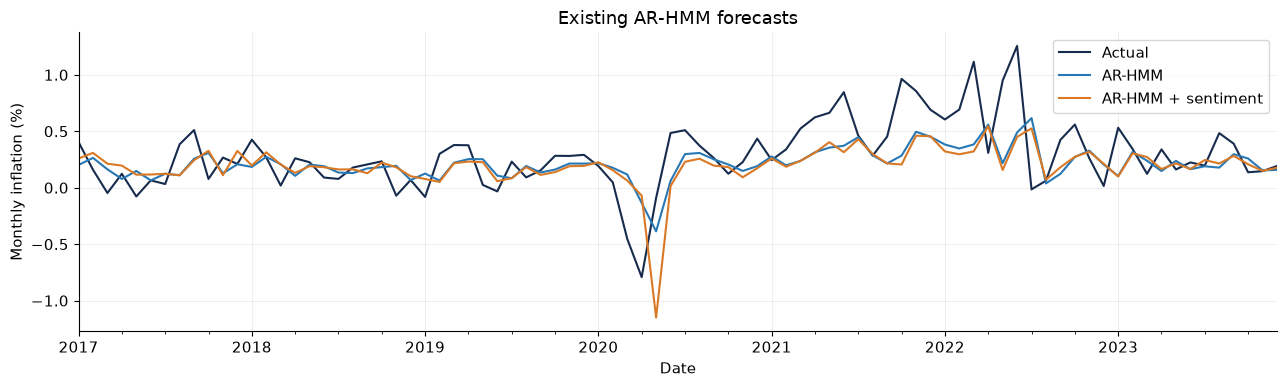

In [34]:
display(metrics.loc[metrics['model'].isin(['HMM', 'AR-HMM', 'AR-HMM + sentiment'])].round(4))
display(pd.DataFrame({'HMM state mean': baseline_parameters['HMM']['state_means']}))
ax = forecasts.set_index('Date')[['Actual', 'AR-HMM', 'AR-HMM + sentiment']].plot(
    figsize=(13, 4), title='Existing AR-HMM forecasts', ylabel='Monthly inflation (%)',
    color=['#172b4d', '#2878b5', '#d97925'],
)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Macroeconomic indicators**


,model,macro_count,rmse,mae,mean_error_actual_minus_forecast,rmse_improvement_pct
0,Inflation + Oil + Unemployment,2,0.2617,0.1958,0.0703,0.9069
1,Inflation + Oil + Unemployment + Industry,3,0.2627,0.1968,0.0710,0.5187
2,Inflation only (lag 1),0,0.2641,0.1950,0.0535,0.0000
3,Inflation + Fed rate,1,0.2649,0.1983,0.0421,-0.3169
4,Inflation + Oil + Unemployment + Fed rate,3,0.2649,0.2015,0.0540,-0.3214
5,Inflation + Oil + Unemployment + Industry + Fe...,4,0.2654,0.2030,0.0541,-0.4808
6,Inflation + Oil + Industry + Fed rate,3,0.2674,0.2010,0.0633,-1.2594
7,Inflation + Oil + Industry,2,0.2679,0.2001,0.0760,-1.4506
8,Inflation + Unemployment,1,0.2682,0.1967,0.0522,-1.5646
9,Inflation + Oil,1,0.2689,0.1946,0.0750,-1.8333


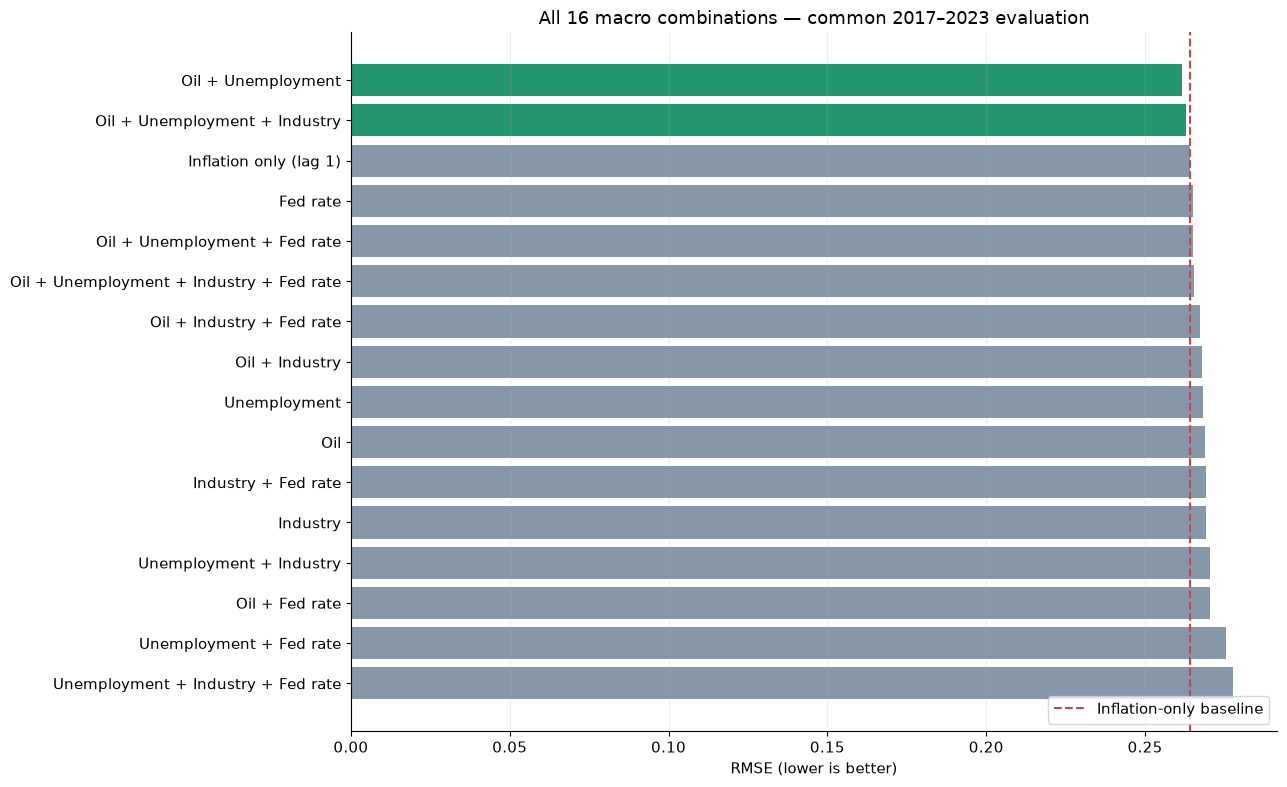

In [35]:
columns = ['model', 'macro_count', 'rmse', 'mae', 'mean_error_actual_minus_forecast', 'rmse_improvement_pct']
display(macro_metrics[columns].round(4))
plot_data = macro_metrics.sort_values('rmse', ascending=False)
colors = ['#23956f' if x > 0 else '#8697aa' for x in plot_data['rmse_improvement_pct']]
fig, ax = plt.subplots(figsize=(13, 8))
ax.barh(plot_data['model'].str.replace('Inflation + ', '', regex=False), plot_data['rmse'], color=colors)
base_name = 'Inflation only (lag 1)'
base_rmse = float(macro_metrics.loc[macro_metrics['model'].eq(base_name), 'rmse'].iloc[0])
ax.axvline(base_rmse, color='#c64747', linestyle='--', label='Inflation-only baseline')
ax.set(xlabel='RMSE (lower is better)', title='All 16 macro combinations — common 2017–2023 evaluation')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()


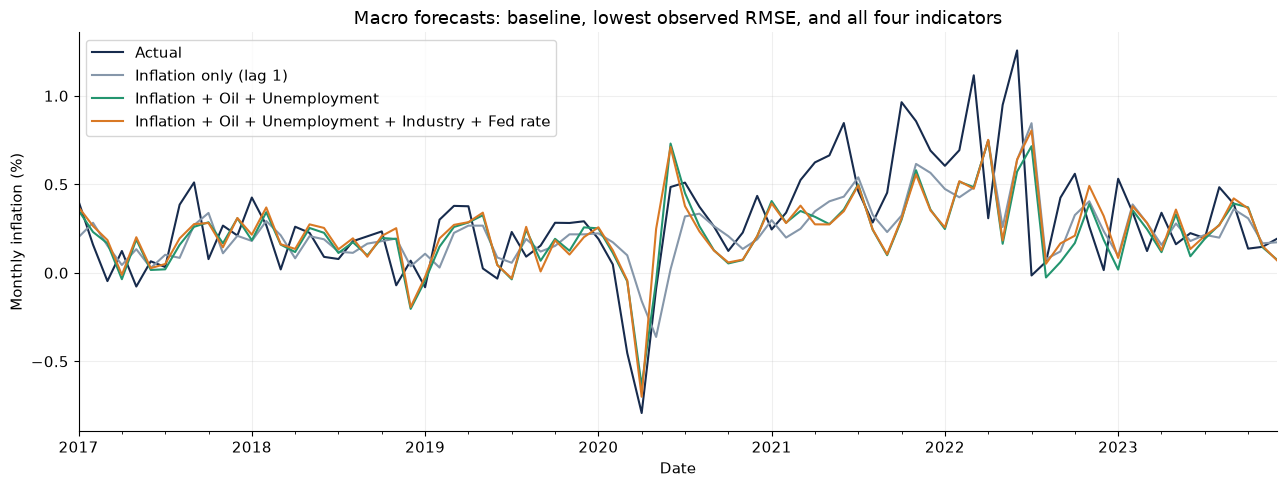

In [36]:
best = macro_metrics.iloc[0]
full_name = 'Inflation + Oil + Unemployment + Industry + Fed rate'
full = macro_metrics.loc[macro_metrics['model'].eq(full_name)].iloc[0]
ax = macro_forecasts.set_index('Date')[list(dict.fromkeys(['Actual', base_name, best['model'], full_name]))].plot(
    figsize=(13, 5), ylabel='Monthly inflation (%)',
    title='Macro forecasts: baseline, lowest observed RMSE, and all four indicators',
    color=['#172b4d', '#8697aa', '#23956f', '#d97925'],
)
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


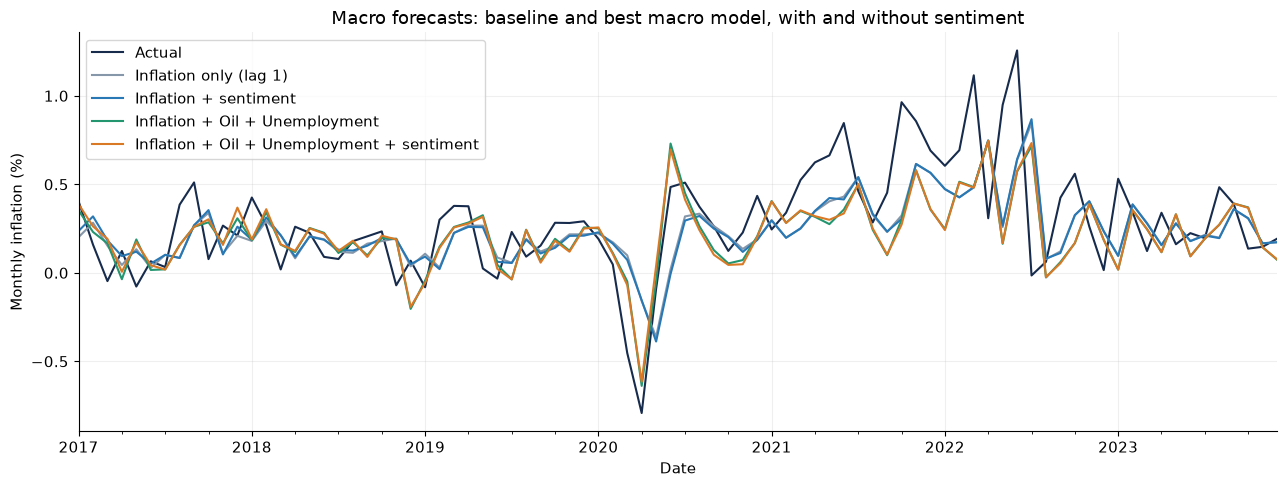

In [37]:
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import importlib
for module_name in (
    'modelling.data_pipeline', 'modelling.evaluation',
    'modelling.models', 'modelling.run_experiments',
):
    importlib.reload(importlib.import_module(module_name))
from modelling.run_experiments import run_sentiment_comparison

sentiment_forecasts, sentiment_metrics, best_macro_name = run_sentiment_comparison(
    PROJECT_ROOT / 'data' / 'processed' / 'modelling_datasets' / 'us_nyt_monthly_experiment.csv',
    macro_dir=MACRO,
)
ax = sentiment_forecasts.set_index('Date')[[
    'Actual', 'Inflation only (lag 1)', 'Inflation + sentiment',
    best_macro_name, best_macro_name + ' + sentiment',
]].plot(
    figsize=(13, 5), ylabel='Monthly inflation (%)',
    title='Macro forecasts: baseline and best macro model, with and without sentiment',
    color=['#172b4d', '#8697aa', '#2878b5', '#23956f', '#d97925'],
)
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


,model,rmse
0,Inflation + Oil + Unemployment,0.2617
1,Inflation + Oil + Unemployment + sentiment,0.2638
2,Inflation only (lag 1),0.2641
3,Inflation + sentiment,0.2660


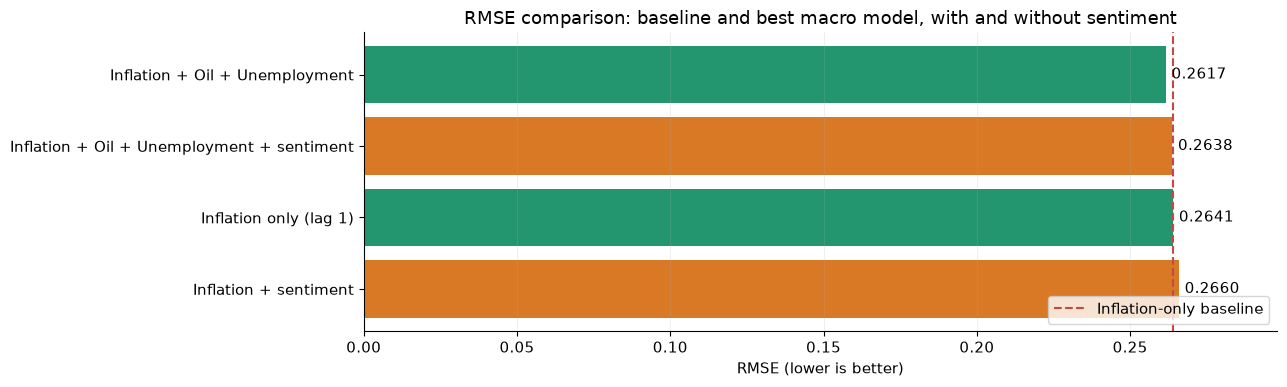

In [38]:
rmse_comparison = sentiment_metrics[['model', 'rmse']].sort_values('rmse').reset_index(drop=True)
display(rmse_comparison.round(4))

plot_data = rmse_comparison.sort_values('rmse', ascending=False)
fig, ax = plt.subplots(figsize=(13, 4))
bars = ax.barh(
    plot_data['model'], plot_data['rmse'],
    color=['#d97925' if 'sentiment' in model else '#23956f' for model in plot_data['model']],
)
reference_rmse = float(rmse_comparison.loc[
    rmse_comparison['model'].eq('Inflation only (lag 1)'), 'rmse'
].iloc[0])
ax.axvline(reference_rmse, color='#c64747', linestyle='--', label='Inflation-only baseline')
ax.bar_label(bars, fmt='%.4f', padding=4)
ax.set(xlabel='RMSE (lower is better)', title='RMSE comparison: baseline and best macro model, with and without sentiment')
ax.set_xlim(0, float(plot_data['rmse'].max()) * 1.12)
ax.grid(axis='x', alpha=0.2)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()
